# QE013: How a Qubit Forgets

**Noise, memory and quantum trajectories: from T₂\* and spin echoes to an environment that remembers.**

No qubit is alone. It is coupled to an **environment**: fluctuating fields, nuclear spins, phonons, electromagnetic
modes. That coupling makes it lose its quantum information, which is **decoherence**. This exercise builds the subject
from the bottom up, using one idea throughout: describe the qubit by many random **trajectories** (pure states) and
average them.

* **Part A (one exact answer, Euler-style):** a qubit dephased by coloured noise. When has it lost coherence? The
  answer has a closed form involving the Lambert W function.
* **Part B1:** fast versus slow noise: *motional narrowing*, T₂\*, and why a **spin echo** helps.
* **Part B2:** **1/f noise**, the noise that limits real spin and superconducting qubits.
* **Part B3:** a *quantum* environment with **memory**, solved exactly with the **hierarchy of pure states (HOPS)** and
  checked against an independent exact method. The usual memoryless (Markov) theory fails, and classical noise heats
  the qubit where a quantum bath cools it.
* **Animations:** trajectories fanning out and refocusing in a spin echo, and energy sloshing between a qubit and its
  environment's memory.

### Words used in this notebook

| term | meaning |
|---|---|
| **open quantum system** | a system (here, one qubit) coupled to a much larger environment (the **bath**) |
| **Bloch vector** | the arrow representing the qubit state; length 1 = pure, shorter = mixed (information lost) |
| **coherence** | the length of the Bloch vector in the equator plane; it carries the quantum superposition |
| **dephasing / T₂** | loss of coherence; T₂ = time for coherence to drop to 1/e ≈ 0.37 |
| **relaxation / T₁** | loss of energy: the excited state decays towards the ground state |
| **Ramsey experiment** | prepare a superposition, wait, measure coherence. Its decay time for slow noise is called **T₂\*** |
| **Hahn (spin) echo** | flip the qubit (π pulse) halfway through; phases picked up before and after cancel if the noise is slow |
| **Ornstein–Uhlenbeck (OU) noise** | the simplest coloured noise: random, with correlation $\sigma^2 e^{-|\tau|/\tau_c}$ |
| **correlation time τ_c** | how long the noise "remembers" its value; small = fast noise, large = slow noise |
| **motional narrowing** | the counter-intuitive fact that *faster* noise destroys coherence *more slowly* |
| **1/f noise** | noise whose power grows at low frequency like 1/f; built here from many OU processes |
| **Markovian / non-Markovian** | memoryless environment / environment with memory, so information can flow back |
| **Lindblad master equation** | the standard memoryless equation for an open system |
| **quantum trajectory** | one random pure-state history; averaging many gives the true (mixed) state |
| **HOPS** | hierarchy of pure states: an exact trajectory method for environments with memory |
| **pseudomode** | an exact trick: replace a Lorentzian bath by one damped harmonic oscillator |
| **Lambert W** | the function solving $w e^{w} = y$; it appears whenever $x$ and $e^{x}$ are mixed in one equation |
| **random seed** | fixes the random draws so every run gives the same numbers |

This notebook needs `numpy`, `scipy`, `pandas` and `matplotlib` (Pillow for the GIFs comes with matplotlib). It runs in
about three minutes and writes two GIF animations next to itself.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from scipy.linalg import expm
from scipy.optimize import brentq
from scipy.special import lambertw

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 10})
BLUE, ORANGE, GREEN, GRAY, INK, BG = "#2a78d6", "#eb6834", "#1f9e6e", "#8a8984", "#0b0b0b", "#fcfcfb"
rng = np.random.default_rng(13)                                  # random seed

SX = np.array([[0, 1], [1, 0]], complex)
SZ = np.array([[1, 0], [0, -1]], complex)                        # basis: (excited, ground)

## Part A: when has the qubit forgotten?

A qubit starts in the superposition $(|0\rangle + |1\rangle)/\sqrt2$ (Bloch vector on the equator). A fluctuating field
shifts its frequency: $H(t) = \tfrac12\,\xi(t)\,\sigma_z$, where $\xi(t)$ is Gaussian OU noise with

$$\langle \xi(t)\,\xi(s)\rangle = \sigma^2\, e^{-|t-s|/\tau_c}.$$

Each trajectory picks up a random phase $\varphi(t) = \int_0^t \xi$. Averaging $e^{-i\varphi}$ over the Gaussian noise
gives the coherence exactly:

$$C(t) = \big|\langle e^{-i\varphi(t)}\rangle\big| = \exp\!\Big[-\sigma^2\tau_c^2\Big(\tfrac{t}{\tau_c} - 1 + e^{-t/\tau_c}\Big)\Big].$$

**Task:** with $\sigma = 1$ and $\tau_c = 1$ (say, in µs⁻¹ and µs), find the dephasing time $T_2$ where $C(T_2) = 1/e$,
and report

$$A = \lfloor 10^6\, T_2 \rfloor .$$

*Check value:* for fast noise, $\tau_c = 0.1$, the same condition gives $T_2 = 10.1$.

**Closed form.** With $x = T_2/\tau_c$ and $\sigma\tau_c = 1$ the condition is $x - 2 + e^{-x} = 0$. Substitute
$x = 2 + w$: then $w\,e^{w} = -e^{-2}$, so $w = W_0(-e^{-2})$ and $x = 2 + W_0(-e^{-2})$.

In [2]:
coherence_ramsey = lambda t, sigma, tc: np.exp(-(sigma * tc) ** 2 * (t / tc - 1 + np.exp(-t / tc)))
coherence_echo = lambda t, sigma, tc: np.exp(-(sigma * tc) ** 2 * (t / tc - 3 + 4 * np.exp(-t / (2 * tc)) - np.exp(-t / tc)))

def T2(sigma, tc, curve=coherence_ramsey):
    return brentq(lambda t: curve(t, sigma, tc) - np.exp(-1), 1e-9, 1e6)

print(f"check, tau_c = 0.1      : T2 = {T2(1, 0.1):.6f}")
T2_numeric = T2(1, 1)
T2_closed = 2 + lambertw(-np.exp(-2)).real
print(f"tau_c = 1, root finding : T2 = {T2_numeric:.10f}")
print(f"tau_c = 1, Lambert W    : T2 = {T2_closed:.10f}")
A = int(np.floor(1e6 * T2_closed))
print(f"\nANSWER  A = {A}")

check, tau_c = 0.1      : T2 = 10.100000
tau_c = 1, root finding : T2 = 1.8414056604
tau_c = 1, Lambert W    : T2 = 1.8414056604

ANSWER  A = 1841405


**Monte Carlo check.** Generate OU noise exactly (each step $\xi \to \xi e^{-\Delta t/\tau_c} + \sigma\sqrt{1 - e^{-2\Delta t/\tau_c}}\,\eta$),
integrate the phase of 20,000 trajectories, and average.

In [3]:
def ou_noise(n_traj, n_steps, dt, sigma, tc):
    a = np.exp(-dt / tc); b = sigma * np.sqrt(1 - a ** 2)
    xi = np.empty((n_steps + 1, n_traj)); xi[0] = sigma * rng.standard_normal(n_traj)
    for k in range(n_steps):
        xi[k + 1] = a * xi[k] + b * rng.standard_normal(n_traj)
    return xi

def phases(xi, dt):
    inc = 0.5 * (xi[1:] + xi[:-1]) * dt                              # trapezoid rule
    return np.concatenate([[np.zeros(xi.shape[1])], np.cumsum(inc, 0)])

dt, T_end = 0.01, 4.0
xi = ou_noise(20000, int(T_end / dt), dt, 1.0, 1.0)
phi = phases(xi, dt)
t = np.arange(phi.shape[0]) * dt
C_mc = np.abs(np.mean(np.exp(-1j * phi), axis=1))
print(f"Monte Carlo coherence at t = T2: {np.interp(T2_closed, t, C_mc):.4f}   (exact 1/e = {np.exp(-1):.4f})")

Monte Carlo coherence at t = T2: 0.3583   (exact 1/e = 0.3679)


## Part B1: fast noise, slow noise, and the spin echo

The formula has two limits:

* **fast noise** ($\tau_c \ll T_2$): the phase performs a random walk, coherence decays as a pure exponential, and
  $T_2 \approx 1/(\sigma^2\tau_c)$. *Faster noise is less harmful*: motional narrowing.
* **slow noise** ($\tau_c \gg T_2$): every trajectory just sees a random but constant frequency, coherence decays as a
  Gaussian, and $T_2^\ast \approx \sqrt2/\sigma$, independent of $\tau_c$.

A **Hahn echo** flips the qubit at $t/2$, so phase collected in the first half is subtracted in the second half:
$\varphi_\text{echo} = \int_0^{t/2}\xi - \int_{t/2}^{t}\xi$. Slow noise cancels almost completely. The exact echo
coherence is $\exp[-\sigma^2\tau_c^2(x - 3 + 4e^{-x/2} - e^{-x})]$ with $x = t/\tau_c$, checked by Monte Carlo below.

Monte Carlo points in 2 s


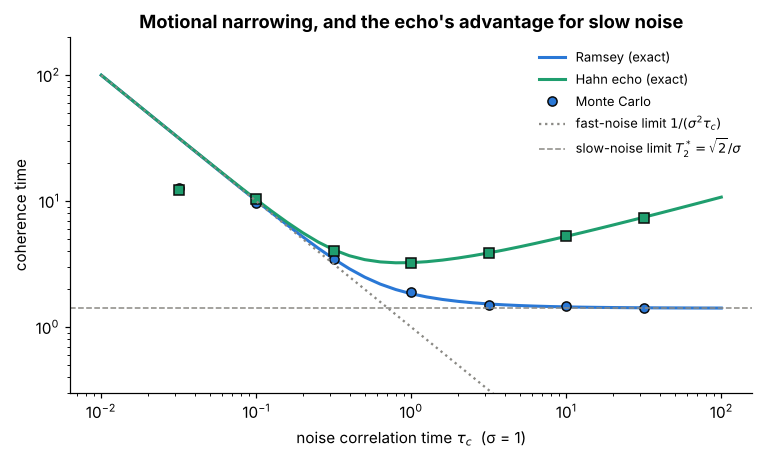

In [4]:
def mc_T2(tc, echo, n_traj=4000, sigma=1.0):
    guess = T2(sigma, tc, coherence_echo if echo else coherence_ramsey)
    T_ = 2.0 * guess; n = 400; dt_ = T_ / n
    xi_ = ou_noise(n_traj, n, dt_, sigma, tc)
    inc = 0.5 * (xi_[1:] + xi_[:-1]) * dt_
    cum = np.concatenate([[np.zeros(n_traj)], np.cumsum(inc, 0)])
    ts_ = np.arange(n + 1) * dt_
    if not echo:
        C_ = np.abs(np.mean(np.exp(-1j * cum), 1))
    else:                                                        # echo of total duration t uses phase(t/2) twice
        half = np.arange(0, n + 1, 2) // 2
        ph = 2 * cum[half] - cum[np.arange(0, n + 1, 2)]
        C_ = np.abs(np.mean(np.exp(-1j * ph), 1)); ts_ = ts_[::2]
    return ts_[np.argmax(C_ < np.exp(-1))]

tcs = np.logspace(-2, 2, 41)
exact_ramsey = [T2(1, tc) for tc in tcs]
exact_echo = [T2(1, tc, coherence_echo) for tc in tcs]
mc_points = np.logspace(-1.5, 1.5, 7)
t0 = time.time()
mc_r = [mc_T2(tc, False) for tc in mc_points]; mc_e = [mc_T2(tc, True) for tc in mc_points]
print(f"Monte Carlo points in {time.time() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.loglog(tcs, exact_ramsey, color=BLUE, lw=2, label="Ramsey (exact)")
ax.loglog(tcs, exact_echo, color=GREEN, lw=2, label="Hahn echo (exact)")
ax.loglog(mc_points, mc_r, "o", color=BLUE, mec=INK, label="Monte Carlo")
ax.loglog(mc_points, mc_e, "s", color=GREEN, mec=INK)
ax.loglog(tcs, 1 / tcs, ":", color=GRAY, label=r"fast-noise limit $1/(\sigma^2\tau_c)$")
ax.axhline(np.sqrt(2), color=GRAY, ls="--", lw=1, label=r"slow-noise limit $T_2^* = \sqrt{2}/\sigma$")
ax.set_ylim(0.3, 200); ax.set_xlabel(r"noise correlation time $\tau_c$  (σ = 1)"); ax.set_ylabel("coherence time")
ax.legend(frameon=False, fontsize=8.5); ax.set_title("Motional narrowing, and the echo's advantage for slow noise")
plt.show()

For fast noise Ramsey and echo give the same $T_2$: there is nothing slow to cancel. For slow noise the Ramsey time
saturates at $T_2^\ast = \sqrt2$, while the echo time keeps growing, as $T_2^\text{echo} \propto \tau_c^{1/3}$.

## Part B2: 1/f noise

Real spin and superconducting qubits suffer **1/f noise**: fluctuators on all time scales at once. A standard model adds
many independent OU processes whose correlation times are spread evenly on a log scale. Each contributes a Lorentzian
spectrum, and together they give $S(f) \propto 1/f$ over the covered decades. Here: 25 fluctuators with
$\tau_c$ from 0.01 to 100, sharing a total noise strength $\sigma = 1$.

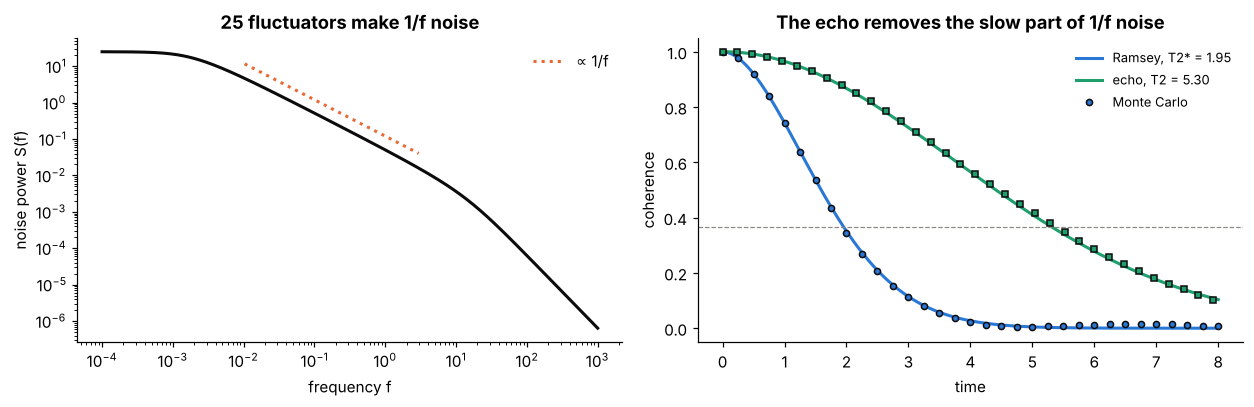

1/f noise: T2* = 1.949, T2(echo) = 5.301  (echo gains a factor 2.72)


In [5]:
tau_k = np.logspace(-2, 2, 25); var_k = np.full(25, 1.0 / 25)          # sum of variances = sigma^2 = 1
ramsey_1f = lambda t: np.prod([coherence_ramsey(t, np.sqrt(v), tk) for v, tk in zip(var_k, tau_k)], 0)
echo_1f = lambda t: np.prod([coherence_echo(t, np.sqrt(v), tk) for v, tk in zip(var_k, tau_k)], 0)
T2s_1f = brentq(lambda t: ramsey_1f(t) - np.exp(-1), 1e-6, 1e4)
T2e_1f = brentq(lambda t: echo_1f(t) - np.exp(-1), 1e-6, 1e4)

f = np.logspace(-4, 3, 300)
S = sum(2 * v * tk / (1 + (2 * np.pi * f * tk) ** 2) for v, tk in zip(var_k, tau_k))

# Monte Carlo: Ramsey and echo with the full 1/f noise
n_traj, dt_, T_ = 4000, 0.01, 8.0; n = int(T_ / dt_)
total = sum(ou_noise(n_traj, n, dt_, np.sqrt(v), tk) for v, tk in zip(var_k, tau_k))
cum = np.concatenate([[np.zeros(n_traj)], np.cumsum(0.5 * (total[1:] + total[:-1]) * dt_, 0)])
tt = np.arange(n + 1) * dt_
C_ramsey_mc = np.abs(np.mean(np.exp(-1j * cum), 1))
even = np.arange(0, n + 1, 2)
C_echo_mc = np.abs(np.mean(np.exp(-1j * (2 * cum[even // 2] - cum[even])), 1))

fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8))
ax[0].loglog(f, S, color=INK, lw=2)
ax[0].loglog(f[(f > 0.01) & (f < 3)], 0.12 / f[(f > 0.01) & (f < 3)], ":", color=ORANGE, lw=2, label="∝ 1/f")
ax[0].set_xlabel("frequency f"); ax[0].set_ylabel("noise power S(f)"); ax[0].legend(frameon=False)
ax[0].set_title("25 fluctuators make 1/f noise")
ax[1].plot(tt, ramsey_1f(tt), color=BLUE, lw=2, label=f"Ramsey, T2* = {T2s_1f:.2f}")
ax[1].plot(tt, echo_1f(tt), color=GREEN, lw=2, label=f"echo, T2 = {T2e_1f:.2f}")
ax[1].plot(tt[::25], C_ramsey_mc[::25], "o", ms=4, color=BLUE, mec=INK, label="Monte Carlo")
ax[1].plot(tt[even][::12], C_echo_mc[::12], "s", ms=4, color=GREEN, mec=INK)
ax[1].axhline(np.exp(-1), color=GRAY, lw=0.8, ls="--")
ax[1].set_xlabel("time"); ax[1].set_ylabel("coherence"); ax[1].legend(frameon=False, fontsize=8.5)
ax[1].set_title("The echo removes the slow part of 1/f noise")
plt.tight_layout(); plt.show()
print(f"1/f noise: T2* = {T2s_1f:.3f}, T2(echo) = {T2e_1f:.3f}  (echo gains a factor {T2e_1f / T2s_1f:.2f})")

## Part B3: an environment with memory

So far the environment was *classical noise*. A real environment is a *quantum* system. It can absorb the qubit's
energy and, if it has **memory**, give it back. Take a qubit with $H_S = \tfrac{\omega}{2}\sigma_z$ coupled through
$L = \sigma_x$ to a zero-temperature bath whose correlation function is

$$\alpha(\tau) = g\, e^{-(\gamma + i\Omega)\tau}, \qquad \tau \ge 0 ,$$

a Lorentzian bath centred at frequency $\Omega$ with width $\gamma$. A small $\gamma$ means a long memory.

**HOPS.** The exact reduced state is an average over pure-state trajectories $\psi_t(z^\ast)$ driven by complex
coloured noise $z_t$ with $\mathbb E[z_t z_s^\ast] = \alpha(t-s)$. For this exponential $\alpha$ the memory can be
carried by a hierarchy of auxiliary states $\psi^{(k)}$:

$$\partial_t\psi^{(k)} = \big(-iH_S + L z_t^\ast - k w\big)\psi^{(k)} + k\,g\,L\,\psi^{(k-1)} - L^\dagger\psi^{(k+1)},
\qquad w = \gamma + i\Omega,$$

truncated at depth $K$. The physical state is $\rho_t = \mathbb E\big[|\psi^{(0)}_t\rangle\langle\psi^{(0)}_t|\big]$.

**Independent exact check: pseudomode.** The same Lorentzian bath is reproduced exactly by one harmonic oscillator of
frequency $\Omega$, coupled as $\sqrt g\,\sigma_x(a + a^\dagger)$ and damped at rate $2\gamma$. That is a small
Lindblad problem we can solve directly.

**First test, pure dephasing** ($H_S = 0$, $L = \sigma_z$), where the exact answer is known:
$C(t) = \exp\!\big[-4\,\mathrm{Re}\,G(t)\big]$ with $G(t) = \frac{g}{w^2}\big(wt - 1 + e^{-wt}\big)$.

In [6]:
def hops(H, L, g, w, psi0, T, dt, K, n_traj):
    n_t = int(round(T / dt)); h = dt / 2
    decay = np.exp(-w * h); amp = np.sqrt(g * (1 - np.exp(-2 * w.real * h)))
    cn = lambda: (rng.standard_normal(n_traj) + 1j * rng.standard_normal(n_traj)) / np.sqrt(2)
    z = np.empty((2 * n_t + 1, n_traj), complex); z[0] = np.sqrt(g) * cn()
    for k in range(2 * n_t):                                       # complex OU noise on half steps
        z[k + 1] = decay * z[k] + amp * cn()
    kk = np.arange(K + 1)[None, :, None]; Ld = L.conj().T

    def rhs(psi, zc):
        out = psi @ (-1j * H).T + zc[:, None, None] * (psi @ L.T) - kk * w * psi
        out[:, 1:] += kk[:, 1:] * g * (psi[:, :-1] @ L.T)
        out[:, :-1] -= psi[:, 1:] @ Ld.T
        return out

    psi = np.zeros((n_traj, K + 1, 2), complex); psi[:, 0] = psi0
    rho = [np.einsum("ni,nj->ij", psi[:, 0], psi[:, 0].conj()) / n_traj]
    for k in range(n_t):                                           # Runge-Kutta 4
        z0, z1, z2 = z[2 * k].conj(), z[2 * k + 1].conj(), z[2 * k + 2].conj()
        k1 = rhs(psi, z0); k2 = rhs(psi + h * k1, z1); k3 = rhs(psi + h * k2, z1); k4 = rhs(psi + dt * k3, z2)
        psi = psi + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        rho.append(np.einsum("ni,nj->ij", psi[:, 0], psi[:, 0].conj()) / n_traj)
    return np.arange(n_t + 1) * dt, np.array(rho)

g_d, w_d = 0.5, 1.0 + 0.5j
t0 = time.time()
t_d, rho_d = hops(np.zeros((2, 2)), SZ, g_d, w_d, np.array([1, 1]) / np.sqrt(2), 4.0, 0.01, 6, 3000)
G = g_d / w_d ** 2 * (w_d * t_d - 1 + np.exp(-w_d * t_d))
check = pd.DataFrame({"t": t_d[::100], "HOPS": 2 * np.abs(rho_d[::100, 0, 1]), "exact": np.exp(-4 * G.real)[::100]})
print(f"HOPS, 3000 trajectories, depth 6: {time.time() - t0:.0f} s")
check.round(4).set_index("t").T

HOPS, 3000 trajectories, depth 6: 8 s


t,0.0,1.0,2.0,3.0,4.0
HOPS,1.0,0.4895,0.1192,0.0227,0.0041
exact,1.0,0.4847,0.1148,0.0228,0.0045


**Now the real test, relaxation with memory.** The qubit starts excited. We compare four descriptions in two regimes:

* **HOPS** (exact, trajectories) and **pseudomode** (exact, independent);
* **Markov (Lindblad)**: memoryless jumps at the Golden-Rule rates read off the bath spectrum,
  $\Gamma_\downarrow = 2g\gamma/(\gamma^2 + (\omega - \Omega)^2)$ for emission and
  $\Gamma_\uparrow = 2g\gamma/(\gamma^2 + (\omega + \Omega)^2)$ for absorption. (A Lorentzian spectrum has a small tail at
  negative frequencies, so this toy bath can excite the qubit slightly even at zero temperature.)
* **classical noise** with the *same* correlation, $\langle\xi\xi\rangle = \mathrm{Re}\,\alpha$, acting as
  $H = H_S + \xi(t)\sigma_x$.

relaxation runs done in 24 s


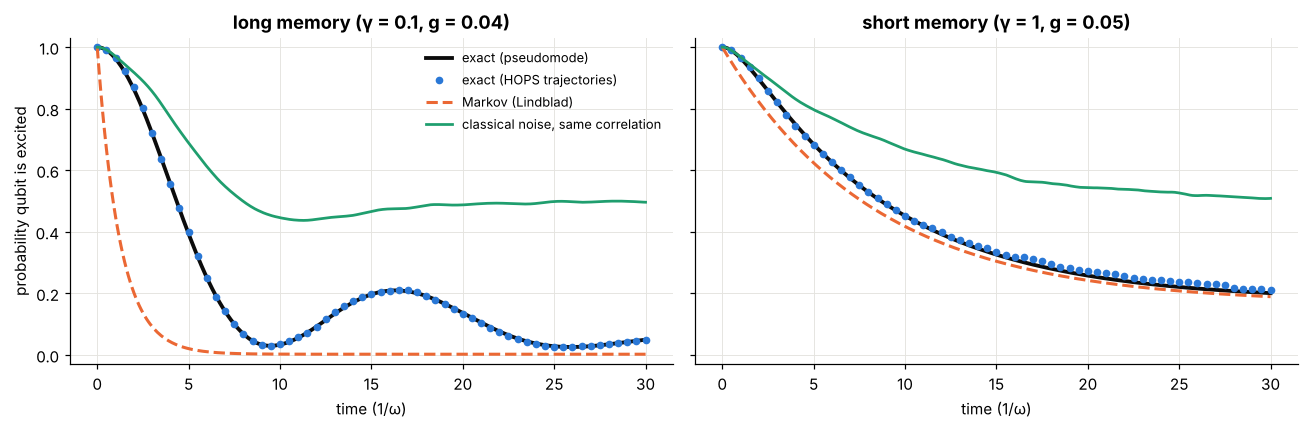

,"long memory (γ = 0.1, g = 0.04)","short memory (γ = 1, g = 0.05)"
"HOPS vs pseudomode, max difference",0.007,0.020
excited probability at t = 30: exact,0.050,0.201
Markov,0.002,0.189
classical noise,0.496,0.509
"Markov vs exact, max difference",0.665,0.074


In [7]:
def pseudomode(om, Om, g, gam, T, dt, n_max=12):
    a = np.diag(np.sqrt(np.arange(1, n_max)), 1); I2, Im = np.eye(2), np.eye(n_max)
    Hf = 0.5 * om * np.kron(SZ, Im) + Om * np.kron(I2, a.T @ a) + np.sqrt(g) * np.kron(SX, a + a.T)
    Lm = np.sqrt(2 * gam) * np.kron(I2, a); D = Hf.shape[0]; Id = np.eye(D); LdL = Lm.conj().T @ Lm
    gen = (-1j * (np.kron(Hf, Id) - np.kron(Id, Hf.T)) + np.kron(Lm, Lm.conj())
           - 0.5 * np.kron(LdL, Id) - 0.5 * np.kron(Id, LdL.T))
    prop = expm(gen * dt)
    r = np.kron(np.diag([1.0, 0.0]), np.diag(np.eye(n_max)[0])).reshape(-1).astype(complex)
    pe, nm = [], []
    for _ in range(int(round(T / dt)) + 1):
        R = r.reshape(2, n_max, 2, n_max)
        pe.append(np.einsum("iaia->", R[:1, :, :1, :]).real)
        nm.append(np.einsum("iaib,ba->", R, a.T @ a).real)
        r = prop @ r
    return np.arange(len(pe)) * dt, np.array(pe), np.array(nm)

def classical_noise(om, Om, g, gam, T, dt, n_traj=1000):
    n_t = int(round(T / dt)); h = dt / 2; w = gam + 1j * Om
    decay = np.exp(-w * h); amp = np.sqrt(g * (1 - np.exp(-2 * gam * h)))
    cn = lambda: (rng.standard_normal(n_traj) + 1j * rng.standard_normal(n_traj)) / np.sqrt(2)
    z = np.empty((2 * n_t + 1, n_traj), complex); z[0] = np.sqrt(g) * cn()
    for k in range(2 * n_t):
        z[k + 1] = decay * z[k] + amp * cn()
    xi = np.sqrt(2) * z.real                                       # real noise, <xi xi> = Re alpha
    Hs = 0.5 * om * SZ
    f_ = lambda psi, x: np.einsum("nij,nj->ni", -1j * (Hs[None] + x[:, None, None] * SX[None]), psi)
    psi = np.tile(np.array([1, 0], complex), (n_traj, 1)); pe = [1.0]
    for k in range(n_t):
        x0, x1, x2 = xi[2 * k], xi[2 * k + 1], xi[2 * k + 2]
        k1 = f_(psi, x0); k2 = f_(psi + h * k1, x1); k3 = f_(psi + h * k2, x1); k4 = f_(psi + dt * k3, x2)
        psi = psi + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        pe.append(np.mean(np.abs(psi[:, 0]) ** 2))
    return np.arange(n_t + 1) * dt, np.array(pe)

regimes = {"long memory (γ = 0.1, g = 0.04)": (1.0, 1.0, 0.04, 0.1, 8),
           "short memory (γ = 1, g = 0.05)": (1.0, 1.0, 0.05, 1.0, 6)}
T_rel, dt_rel = 30.0, 0.02
results = {}
t0 = time.time()
for name, (om, Om, g, gam, K) in regimes.items():
    th, rh = hops(0.5 * om * SZ, SX, g, gam + 1j * Om, np.array([1, 0], complex), T_rel, dt_rel, K, 1000)
    tp, pe, nm = pseudomode(om, Om, g, gam, T_rel, 0.1)
    tc_, pc = classical_noise(om, Om, g, gam, T_rel, dt_rel)
    down = 2 * g * gam / (gam ** 2 + (om - Om) ** 2); up = 2 * g * gam / (gam ** 2 + (om + Om) ** 2)
    markov = up / (up + down) + down / (up + down) * np.exp(-(up + down) * tp)
    results[name] = dict(th=th, hops=rh[:, 0, 0].real, tp=tp, pseudo=pe, memory=nm, tc=tc_, classical=pc, markov=markov)
print(f"relaxation runs done in {time.time() - t0:.0f} s")

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, (name, r_) in zip(ax, results.items()):
    a.plot(r_["tp"], r_["pseudo"], color=INK, lw=2.5, label="exact (pseudomode)")
    a.plot(r_["th"][::25], r_["hops"][::25], "o", ms=4, color=BLUE, label="exact (HOPS trajectories)")
    a.plot(r_["tp"], r_["markov"], "--", color=ORANGE, lw=2, label="Markov (Lindblad)")
    a.plot(r_["tc"], r_["classical"], color=GREEN, lw=1.8, label="classical noise, same correlation")
    a.set_title(name); a.set_xlabel("time (1/ω)"); a.grid(color="#e4e3df", lw=0.6)
ax[0].set_ylabel("probability qubit is excited"); ax[0].legend(frameon=False, fontsize=8.5); ax[0].set_ylim(-0.03, 1.03)
plt.tight_layout(); plt.show()

summary = pd.DataFrame({name: {"HOPS vs pseudomode, max difference": np.max(np.abs(np.interp(r_["tp"], r_["th"], r_["hops"]) - r_["pseudo"])),
                               "excited probability at t = 30: exact": r_["pseudo"][-1],
                               "Markov": r_["markov"][-1], "classical noise": r_["classical"][-1],
                               "Markov vs exact, max difference": np.max(np.abs(r_["markov"] - r_["pseudo"]))}
                        for name, r_ in results.items()}).round(3)
summary

What the two regimes show:

* **Two independent exact methods agree.** The HOPS trajectories land on the pseudomode curve, within the statistical
  error of 1,000 trajectories.
* **Long memory: Markov fails completely.** The qubit's energy flows into the bath and *comes back*, giving oscillations
  (vacuum Rabi oscillations) that a memoryless master equation cannot produce.
* **Short memory: Markov is close.** When the bath forgets quickly (γ = 1), the Golden-Rule rates follow the exact
  curve far better: the largest gap is 0.07, against 0.67 with long memory. What is left comes from the bath's finite
  memory and the frequency shift it causes.
* **Classical noise is not a quantum bath.** Noise with the same correlation drives the qubit towards a 50/50 mixture
  (infinite temperature), because classical noise absorbs and emits equally. A zero-temperature quantum bath takes the
  energy and keeps it, so the qubit relaxes to its ground state.

## Animations

**1. Ramsey versus spin echo.** Each dot is one trajectory: a pure state on the equator of the Bloch sphere, seen from
above. Slow noise ($\tau_c = 20$) makes them fan out; the arrow is their average, which is the actual qubit state. On
the right a π pulse at $t = 2$ mirrors every dot, and they **refocus** at $t = 4$.

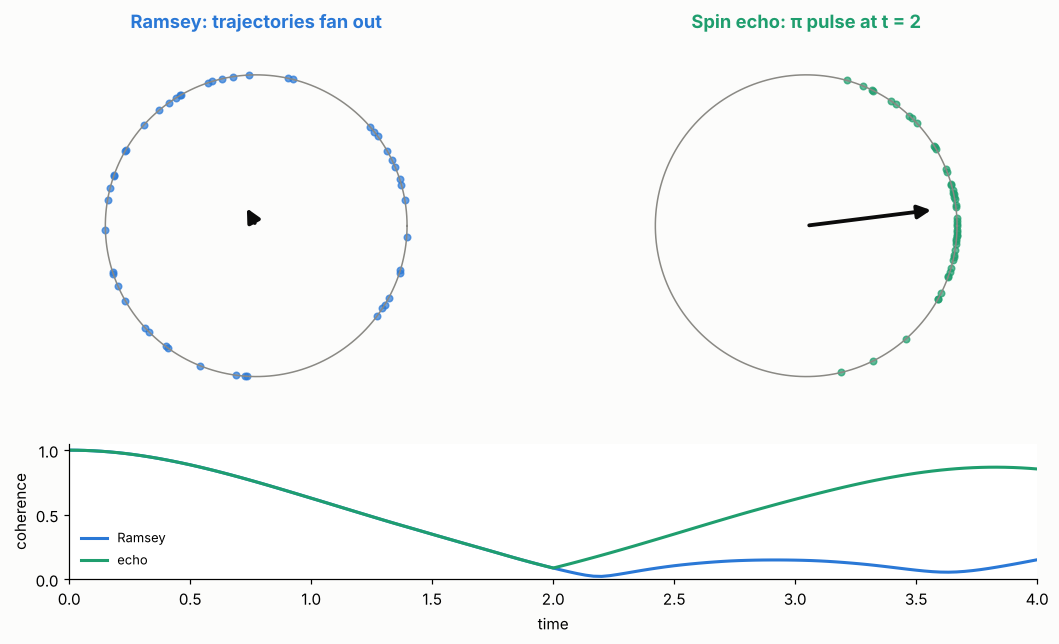

saved qe013_spin_echo.gif (28 s): coherence at t = 4, Ramsey 0.151, echo 0.854


In [8]:
def echo_animation(filename, n_dots=48, tc=20.0, T_=4.0, frames=120, fps=20):
    dt_ = T_ / frames
    xi_ = ou_noise(n_dots, frames, dt_, 1.0, tc)
    cum_ = np.concatenate([[np.zeros(n_dots)], np.cumsum(0.5 * (xi_[1:] + xi_[:-1]) * dt_, 0)])
    half = frames // 2
    phi_r = cum_
    phi_e = np.where(np.arange(frames + 1)[:, None] <= half, cum_, 2 * cum_[half] - cum_)
    ts_ = np.arange(frames + 1) * dt_
    Cr = np.abs(np.mean(np.exp(1j * phi_r), 1)); Ce = np.abs(np.mean(np.exp(1j * phi_e), 1))

    fig = plt.figure(figsize=(10, 5.6), facecolor=BG)
    axr, axe = fig.add_axes([0.03, 0.36, 0.44, 0.6]), fig.add_axes([0.53, 0.36, 0.44, 0.6])
    axc = fig.add_axes([0.08, 0.08, 0.88, 0.22])
    th = np.linspace(0, 2 * np.pi, 200)
    dots, arrows = [], []
    for a, title, col in [(axr, "Ramsey: trajectories fan out", BLUE), (axe, "Spin echo: π pulse at t = 2", GREEN)]:
        a.plot(np.cos(th), np.sin(th), color=GRAY, lw=1); a.set_aspect("equal"); a.axis("off")
        a.set_xlim(-1.2, 1.2); a.set_ylim(-1.2, 1.25); a.set_title(title, fontweight="bold", color=col)
        dots.append(a.scatter(np.ones(n_dots), np.zeros(n_dots), s=18, color=col, alpha=0.7))
        arrows.append(a.annotate("", xy=(1, 0), xytext=(0, 0),
                                 arrowprops=dict(arrowstyle="-|>", color=INK, lw=2.5, mutation_scale=18)))
    flash = axe.text(0, 0, "", ha="center", va="center", fontsize=16, fontweight="bold", color=ORANGE)
    axc.plot(ts_, Cr, color=BLUE, lw=1, alpha=0.3); axc.plot(ts_, Ce, color=GREEN, lw=1, alpha=0.3)
    lr, = axc.plot([], [], color=BLUE, lw=2, label="Ramsey"); le, = axc.plot([], [], color=GREEN, lw=2, label="echo")
    axc.set_xlim(0, T_); axc.set_ylim(0, 1.05); axc.set_xlabel("time"); axc.set_ylabel("coherence")
    axc.legend(frameon=False, fontsize=8.5, loc="lower left"); axc.spines[["top", "right"]].set_visible(False)

    def draw(i):
        i = min(i, frames)
        for k, phi_ in enumerate((phi_r, phi_e)):
            x, y = np.cos(phi_[i]), np.sin(phi_[i])
            dots[k].set_offsets(np.c_[x, y]); arrows[k].xy = (x.mean(), y.mean())
        flash.set_text("π" if half - 2 <= i <= half + 3 else "")
        lr.set_data(ts_[:i + 1], Cr[:i + 1]); le.set_data(ts_[:i + 1], Ce[:i + 1])
        return []

    animation.FuncAnimation(fig, draw, frames=frames + 1 + fps).save(
        filename, writer=animation.PillowWriter(fps=fps), dpi=80, savefig_kwargs={"facecolor": BG})
    draw(frames); plt.show()
    return Cr[-1], Ce[-1]

t0 = time.time()
cr, ce = echo_animation("qe013_spin_echo.gif")
print(f"saved qe013_spin_echo.gif ({time.time() - t0:.0f} s): coherence at t = 4, Ramsey {cr:.3f}, echo {ce:.3f}")

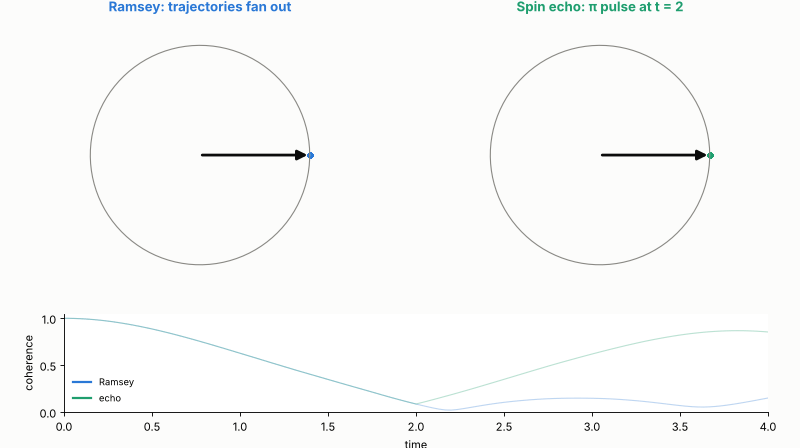

**2. Energy sloshing into the environment's memory.** Using the exact pseudomode solution in the long-memory regime:
the qubit's excitation (blue) flows into the bath's memory mode (orange) and partly comes back before leaking away for
good. The Markov prediction (grey) simply drains away.

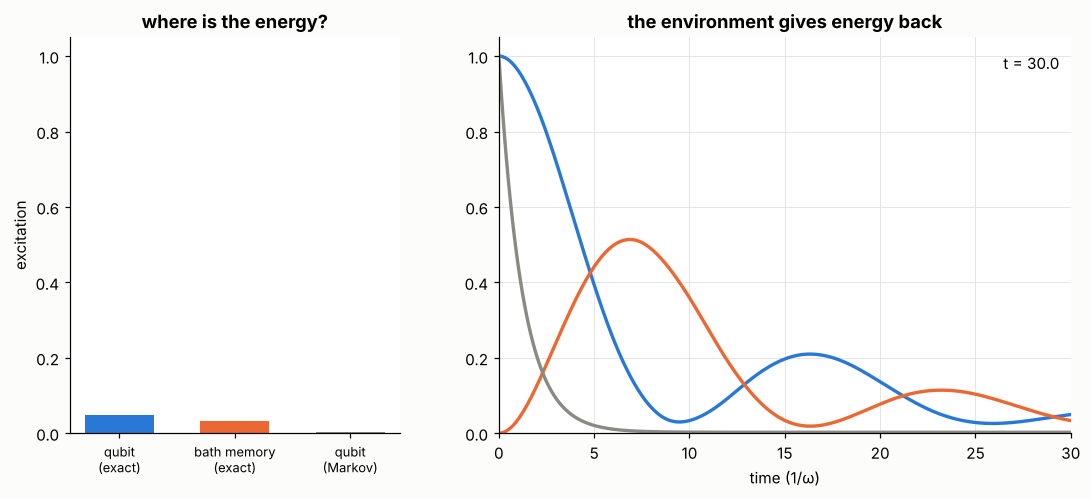

saved qe013_memory.gif (39 s)


In [9]:
def memory_animation(filename, fps=20):
    r_ = results["long memory (γ = 0.1, g = 0.04)"]
    tp, pe, nm = r_["tp"], r_["pseudo"], r_["memory"]
    pm = r_["markov"]
    idx = np.arange(0, len(tp), 2)                                  # 151 frames

    fig = plt.figure(figsize=(10, 4.8), facecolor=BG)
    axb, axt = fig.add_axes([0.06, 0.15, 0.3, 0.75]), fig.add_axes([0.45, 0.15, 0.52, 0.75])
    labels = ["qubit\n(exact)", "bath memory\n(exact)", "qubit\n(Markov)"]
    bars = axb.bar(range(3), [1, 0, 1], color=[BLUE, ORANGE, GRAY], width=0.6)
    axb.set_xticks(range(3)); axb.set_xticklabels(labels, fontsize=8.5); axb.set_ylim(0, 1.05)
    axb.set_ylabel("excitation"); axb.set_title("where is the energy?", fontweight="bold")
    axb.spines[["top", "right"]].set_visible(False)
    for y, col in [(pe, BLUE), (nm, ORANGE), (pm, GRAY)]:
        axt.plot(tp, y, color=col, lw=1, alpha=0.25)
    lines = [axt.plot([], [], color=c, lw=2.2)[0] for c in (BLUE, ORANGE, GRAY)]
    axt.set_xlim(0, tp[-1]); axt.set_ylim(0, 1.05); axt.set_xlabel("time (1/ω)")
    axt.set_title("the environment gives energy back", fontweight="bold")
    axt.spines[["top", "right"]].set_visible(False); axt.grid(color="#e4e3df", lw=0.6)
    clock = axt.text(0.98, 0.92, "", transform=axt.transAxes, ha="right")

    def draw(j):
        k = idx[min(j, len(idx) - 1)]
        for b, v in zip(bars, (pe[k], nm[k], pm[k])):
            b.set_height(v)
        for ln, y in zip(lines, (pe, nm, pm)):
            ln.set_data(tp[:k + 1], y[:k + 1])
        clock.set_text(f"t = {tp[k]:.1f}")
        return []

    animation.FuncAnimation(fig, draw, frames=len(idx) + fps).save(
        filename, writer=animation.PillowWriter(fps=fps), dpi=80, savefig_kwargs={"facecolor": BG})
    draw(len(idx) - 1); plt.show()

t0 = time.time()
memory_animation("qe013_memory.gif")
print(f"saved qe013_memory.gif ({time.time() - t0:.0f} s)")

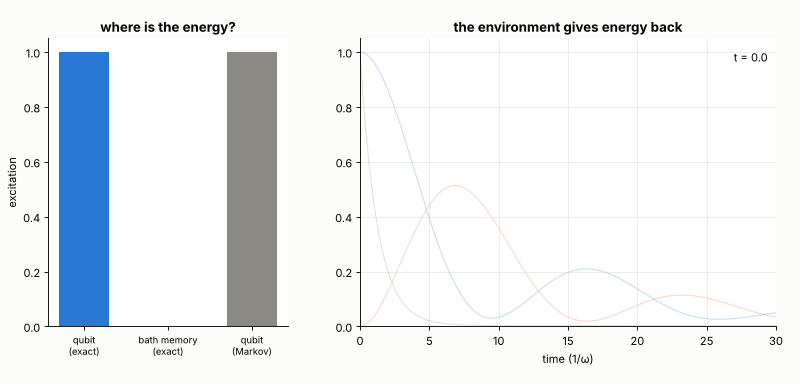

## Conclusions

1. **Exact answer.** For OU noise with σ = τ_c = 1 the coherence falls to 1/e at $T_2 = 2 + W_0(-e^{-2}) = 1.841406$,
   so $A = 1841405$, confirmed by root finding and by 20,000 noise trajectories.
2. **Faster noise is gentler** (motional narrowing). Slow noise sets a floor $T_2^\ast = \sqrt2/\sigma$ that a spin echo
   removes.
3. **1/f noise** mixes all time scales; the echo cancels its slow part and extends coherence by the factor printed in B2.
4. **Memory changes everything.** For a quantum bath with long memory, two independent exact methods (HOPS trajectories
   and the pseudomode) agree, and both show energy returning from the environment. The Markov master equation misses
   this entirely, and classical noise with the same correlation heats the qubit instead of cooling it.

**Try it yourself:** add temperature to the bath (a second, absorbing correlation term), use a sum of exponentials
for a more realistic spectrum, try CPMG sequences with several π pulses against 1/f noise, or switch HOPS to its
normalised (non-linear) version, which needs far fewer trajectories.

### Further reading

* L. Diósi, N. Gisin, W. T. Strunz, *Non-Markovian quantum state diffusion*, Phys. Rev. A 58, 1699 (1998).
* D. Suess, A. Eisfeld, W. T. Strunz, *Hierarchy of stochastic pure states for open quantum system dynamics*,
  Phys. Rev. Lett. 113, 150403 (2014).
* H.-P. Breuer, F. Petruccione, *The Theory of Open Quantum Systems*, Oxford University Press (2002).
* D. Tamascelli, A. Smirne, S. F. Huelga, M. B. Plenio, *Nonperturbative treatment of non-Markovian dynamics of open
  quantum systems*, Phys. Rev. Lett. 120, 030402 (2018).
* E. Paladino, Y. M. Galperin, G. Falci, B. L. Altshuler, *1/f noise: implications for solid-state quantum
  information*, Rev. Mod. Phys. 86, 361 (2014).